In [56]:
from langgraph.graph import StateGraph , START , END
from typing import TypedDict , Dict

In [57]:
class BaseState(TypedDict):
    ball:int
    run:int
    four:int
    six:int
    
    st:float
    bpb:float
    boundary_percent: float
    summery:str

In [58]:
def strike_rate(state:BaseState) -> Dict:
    ball = state['ball']
    run = state['run']    
    st = (run / ball)*100
    return {'st':st}

In [59]:
def batsman_bpb(state:BaseState) -> Dict:
    ball = state['ball']
    fours = state['four']
    sixs = state['six']
    
    bpb = (ball/fours+sixs)
    
    return {'bpb':bpb}

In [60]:
def boundary_percentage(state:BaseState) -> Dict:
    fours = state['four']
    sixs = state['six']
    runs = state['run']
    
    boundary_percent = ((fours*4)+(sixs*6)/(runs))*100
    return {'boundary_percent':boundary_percent}

In [61]:
def create_summery(state:BaseState) -> Dict:
    summery = f'''
    batsman strike rate {state['st']:.2f} and ball per boundary is {state['bpb']:.2f} and boundary percent is {state['boundary_percent']:.2f}
    '''
    return {'summery':summery}

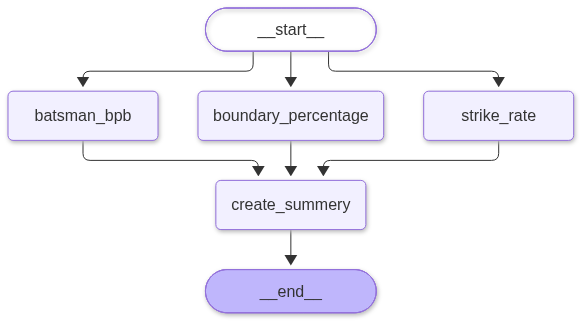

In [62]:
graph = StateGraph(BaseState)

# add node
graph.add_node('strike_rate' , strike_rate)
graph.add_node('batsman_bpb', batsman_bpb)
graph.add_node('boundary_percentage', boundary_percentage)
graph.add_node('create_summery',create_summery)

# add edge
graph.add_edge(START , 'strike_rate')
graph.add_edge(START , 'batsman_bpb')
graph.add_edge(START , 'boundary_percentage')
graph.add_edge('strike_rate' , 'create_summery')
graph.add_edge('batsman_bpb' , 'create_summery')
graph.add_edge('boundary_percentage' , 'create_summery')
graph.add_edge('create_summery' , END)

graph.compile()




In [63]:
work_flow = graph.compile()

In [65]:
initial_state = {'run': 100 , 'ball': 50 , 'four': 10 , 'six': 5}
final_state=work_flow.invoke(initial_state)
print(final_state['summery'])


    batsman strike rate 200.00 and ball per boundary is 10.00 and boundary percent is 4030.00
    
